##Librerías

In [5]:

%pip install requests pandas numpy matplotlib seaborn scikit-learn openpyxl -q

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

def estilo_grafico(titulo, xlabel=None, ylabel=None, leyenda=None, grid=True, rot=0):
    plt.title(titulo, fontsize=14, fontweight="bold")
    if xlabel:
        plt.xlabel(xlabel)
    if ylabel:
        plt.ylabel(ylabel)
    if leyenda is not None:
        plt.legend(**leyenda)
    if grid:
        plt.grid(alpha=0.3)
    if rot:
        plt.xticks(rotation=rot)
    plt.tight_layout()



## 1. Fuente de datos:

El trabajo utiliza series mensuales del BCRP. Se descarga desde 2014 para calcular las variaciones interanuales y se analiza el período 2015 2025.



In [6]:
BASE_URL_BCRP = "https://estadisticas.bcrp.gob.pe/estadisticas/series/api"

SERIES_BCRP = {
    "pbi_indice_desest": "PN01773AM",
    "ipc_var12m": "PN01273PM",
    "tipo_cambio": "PN01246PM",
    "gasto_capital_total": "PN02210FM",
    "gasto_capital_nacional": "PN02211FM",
    "gasto_capital_regional": "PN02406FM",
    "gasto_capital_local": "PN02213FM"
}

NOMBRES_SERIES = {
    "pbi_indice_desest": "PBI", "ipc_var12m": "Inflación",
    "tipo_cambio": "Tipo de cambio", "gasto_capital_total": "Gasto capital total",
    "gasto_capital_nacional": "Gobierno nacional",
    "gasto_capital_regional": "Gobiernos regionales",
    "gasto_capital_local": "Gobiernos locales"
}

# Empezamos en 2014 para calcular el crecimiento interanual desde 2015.
PERIODO_INICIO = "2014-1"
PERIODO_FIN = "2025-12"
filas_bcrp = []

for nombre, codigo in SERIES_BCRP.items():
    url = f"{BASE_URL_BCRP}/{codigo}/json/{PERIODO_INICIO}/{PERIODO_FIN}/esp"
    try:
        respuesta = requests.get(url, timeout=30)
        respuesta.raise_for_status()
        datos = respuesta.json()

        for periodo in datos["periods"]:
            filas_bcrp.append({"periodo": periodo["name"],
                              "serie": nombre, "valor": periodo["values"][0]})
    except (requests.exceptions.RequestException, ValueError, KeyError) as error:
        print("No se pudo descargar", nombre, "-", error)

bcrp_raw = pd.DataFrame(filas_bcrp, columns=["periodo", "serie", "valor"])
if bcrp_raw.empty:
    raise ValueError("No se descargaron datos del BCRP. Revisa la conexión y vuelve a ejecutar.")

display(bcrp_raw.head(10))

,periodo,serie,valor
0,Ene.2014,pbi_indice_desest,145.063403185515
1,Feb.2014,pbi_indice_desest,146.775450836488
2,Mar.2014,pbi_indice_desest,145.81001242282
3,Abr.2014,pbi_indice_desest,146.393851050839
4,May.2014,pbi_indice_desest,145.456142971842
5,Jun.2014,pbi_indice_desest,144.094980905035
6,Jul.2014,pbi_indice_desest,145.887131294091
7,Ago.2014,pbi_indice_desest,146.335649193581
8,Sep.2014,pbi_indice_desest,146.888629947313
9,Oct.2014,pbi_indice_desest,148.317666345584


## Gráfico 1: Cobertura de datos crudos BCRP

Este heatmap muestra la disponibilidad inicial de las series obtenidas desde la API del BCRP antes del proceso de limpieza.

Cada fila representa una serie estadística y cada columna un periodo mensual.
El color indica si existe información disponible o si el valor está ausente.

Permite identificar problemas de cobertura y valores faltantes antes del análisis.

/tmp/ipykernel_1158/3232213902.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cobertura_bcrp, x="cobertura_pct", y="serie", palette="viridis")


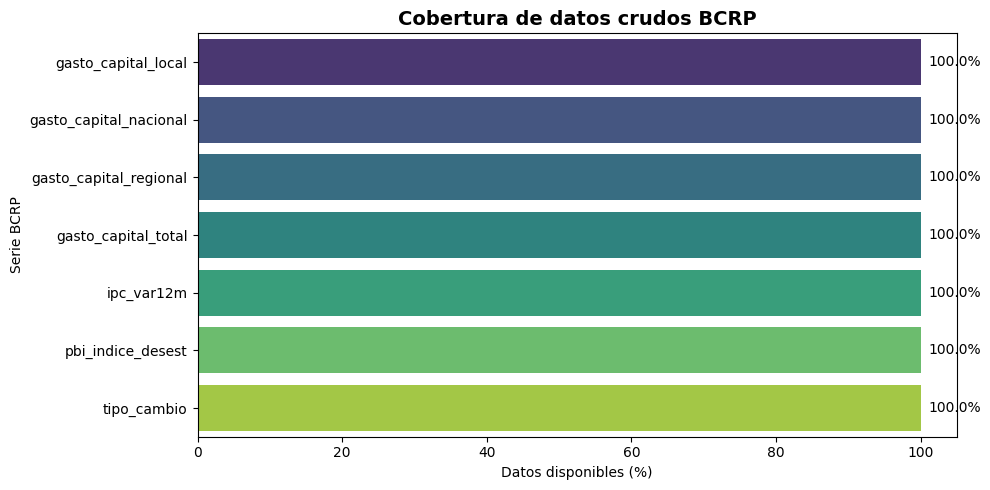

In [7]:
# Gráfico 1: porcentaje de datos disponibles por serie
cobertura_bcrp = bcrp_raw.groupby("serie")["valor"].apply(
    lambda valores: valores.notna().mean() * 100
).reset_index(name="cobertura_pct")

plt.figure(figsize=(10, 5))
sns.barplot(data=cobertura_bcrp, x="cobertura_pct", y="serie", palette="viridis")
for i, valor in enumerate(cobertura_bcrp["cobertura_pct"]):
    plt.text(valor + 1, i, f"{valor:.1f}%", va="center")
plt.xlim(0, 105)
estilo_grafico("Cobertura de datos crudos BCRP", "Datos disponibles (%)", "Serie BCRP", grid=False)
plt.show()

## Gráfico 2: Evolución temporal normalizada

Las series originales presentan diferentes unidades de medida, por lo que se transforman a una base común.

El gráfico permite comparar la trayectoria relativa de los indicadores económicos y fiscales a lo largo del periodo analizado, identificando tendencias, shocks y cambios estructurales.

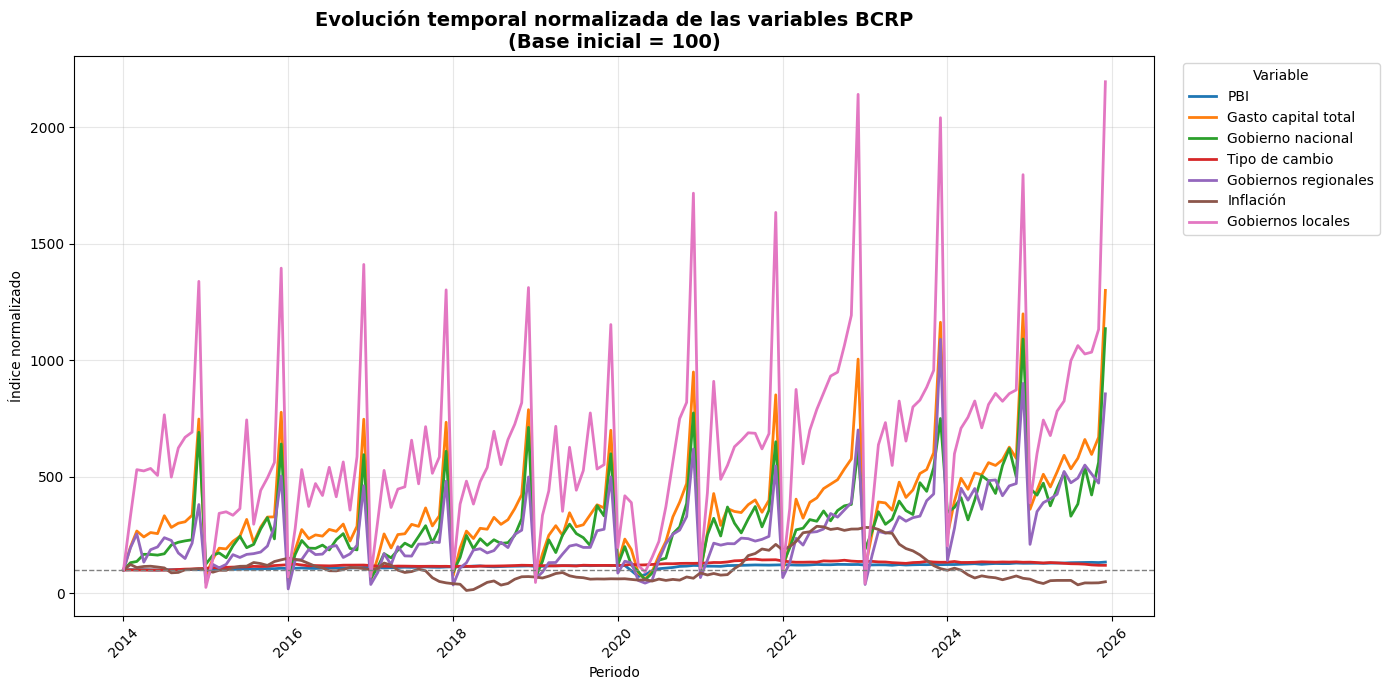

In [8]:
# Gráfico 2: evolución de las variables con base 100
df_evol = bcrp_raw.copy()
# Los meses en español se convierten con nuestro diccionario.
partes = df_evol["periodo"].str.split(".", n=1, expand=True)
df_evol["fecha"] = pd.to_datetime({"year": pd.to_numeric(partes[1], errors="coerce"),
                                   "month": partes[0].map({"Ene": 1, "Feb": 2, "Mar": 3, "Abr": 4, "May": 5, "Jun": 6, "Jul": 7, "Ago": 8, "Sep": 9, "Set": 9, "Oct": 10, "Nov": 11, "Dic": 12}),
                                   "day": 1}, errors="coerce")
df_evol["valor"] = pd.to_numeric(df_evol["valor"], errors="coerce")
df_evol["nombre"] = df_evol["serie"].map(NOMBRES_SERIES)
df_evol = df_evol.sort_values("fecha")
df_evol["indice_normalizado"] = df_evol.groupby("serie")["valor"].transform(lambda x: x / x.iloc[0] * 100)

plt.figure(figsize=(14, 7))
sns.lineplot(data=df_evol, x="fecha", y="indice_normalizado", hue="nombre", palette="tab10", linewidth=2)
plt.axhline(100, linestyle="--", color="gray", linewidth=1)
estilo_grafico("Evolución temporal normalizada de las variables BCRP\n(Base inicial = 100)", "Periodo", "Índice normalizado", leyenda={"title": "Variable", "bbox_to_anchor": (1.02, 1), "loc": "upper left"}, rot=45)
plt.show()

## Gráfico 3: Distribución de las series BCRP

El gráfico muestra la distribución de los valores históricos de las siete series obtenidas del BCRP.

/tmp/ipykernel_1158/2168835647.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_box, x="nombre", y="valor", palette="tab10")


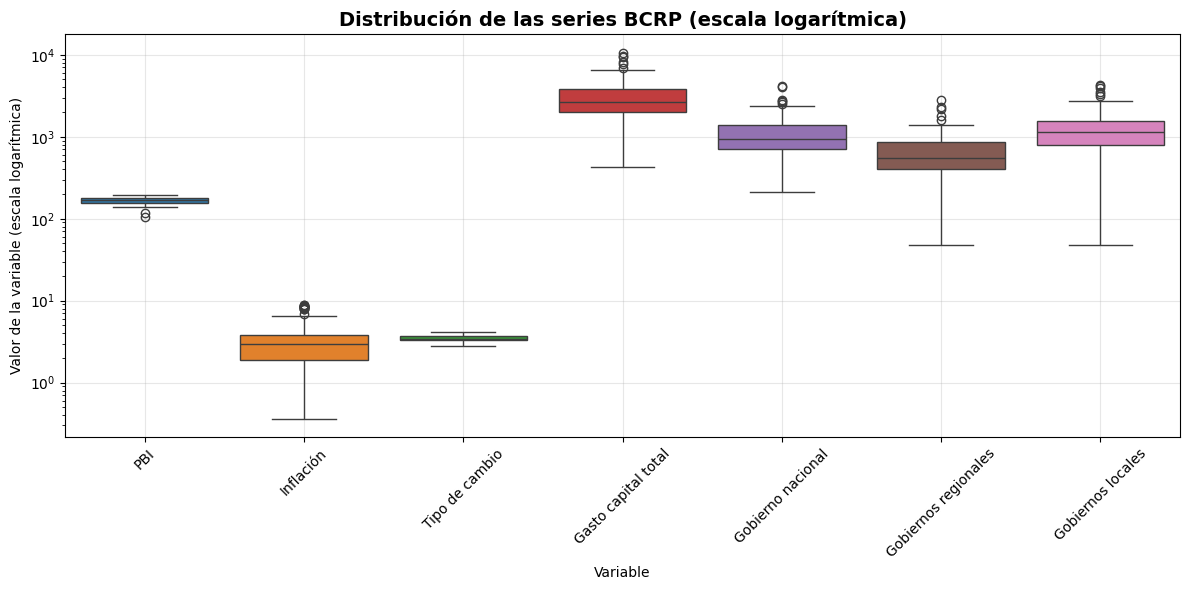

In [9]:
# Gráfico 3: distribución de las series BCRP (escala logarítmica)
df_box = bcrp_raw.copy()
df_box["valor"] = pd.to_numeric(df_box["valor"], errors="coerce")
df_box["nombre"] = df_box["serie"].map(NOMBRES_SERIES)
df_box = df_box.dropna(subset=["valor", "nombre"])
df_box = df_box[df_box["valor"] > 0]  # evita log de valores <= 0

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_box, x="nombre", y="valor", palette="tab10")
plt.yscale("log")
estilo_grafico("Distribución de las series BCRP (escala logarítmica)",
               "Variable", "Valor de la variable (escala logarítmica)", rot=45)
plt.show()

## 2. Limpieza de datos mensuales

Convertimos los periodos en año y mes, pasamos los valores a números y organizamos las siete variables en columnas. El crecimiento interanual del PBI se calcula comparando cada mes con el mismo mes del año anterior.


In [10]:
MESES_BCRP = {
    "Ene": 1, "Feb": 2, "Mar": 3, "Abr": 4, "May": 5, "Jun": 6,
    "Jul": 7, "Ago": 8, "Sep": 9, "Set": 9, "Oct": 10, "Nov": 11, "Dic": 12
}

bcrp_limpio = bcrp_raw.copy()
bcrp_limpio["valor"] = pd.to_numeric(bcrp_limpio["valor"], errors="coerce")


partes = bcrp_limpio["periodo"].str.split(".", n=1, expand=True)
bcrp_limpio["mes"] = partes[0].map(MESES_BCRP)
bcrp_limpio["anio"] = pd.to_numeric(partes[1], errors="coerce")


bcrp_limpio = bcrp_limpio.pivot_table(
    index=["anio", "mes"], columns="serie", values="valor"
).reset_index()
bcrp_limpio.columns.name = None
bcrp_limpio = bcrp_limpio.sort_values(["anio", "mes"]).reset_index(drop=True)

# Calculamos el crecimiento del PBI respecto al mismo mes del año anterior.
bcrp_limpio["pbi_var12m_pct"] = (
    bcrp_limpio["pbi_indice_desest"] / bcrp_limpio["pbi_indice_desest"].shift(12) - 1
) * 100

bcrp_limpio = bcrp_limpio[bcrp_limpio["anio"] >= 2015].reset_index(drop=True)
print("Meses en la base:", len(bcrp_limpio))
display(bcrp_limpio.head(15))

Meses en la base: 132


,anio,mes,gasto_capital_local,gasto_capital_nacional,gasto_capital_regional,gasto_capital_total,ipc_var12m,pbi_indice_desest,tipo_cambio,pbi_var12m_pct
0,2015,1,48.315538,458.975986,114.974780,622.266305,3.073263,147.756580,3.005525,1.856552
1,2015,2,283.383003,600.168246,316.163734,1199.714982,2.768585,148.530398,3.078525,1.195668
2,2015,3,665.954009,635.794698,278.449275,1580.197982,3.020199,149.734247,3.091682,2.691334
3,2015,4,678.795911,559.522726,316.485090,1554.803727,3.017413,152.471072,3.119953,4.151282
4,2015,5,649.974407,747.955830,422.869169,1820.799406,3.366202,148.001598,3.150450,1.749981
5,2015,6,705.081963,899.783294,391.994885,1996.860141,3.544910,150.273069,3.161238,4.287511
6,2015,7,1444.984633,718.786481,425.895322,2589.666436,3.562925,151.302116,3.181250,3.711763
7,2015,8,575.238136,770.529254,434.147583,1779.914973,4.042673,150.176591,3.238357,2.624748
8,2015,9,856.996093,1014.183700,451.677907,2322.857700,3.904555,151.412928,3.218614,3.080088
9,2015,10,961.426791,1193.976344,517.514793,2672.917928,3.660205,153.589303,3.248375,3.554288


## 3. Base nacional para el análisis

La base final contiene una fila por mes y las variables del BCRP: gasto de capital (total y por nivel de gobierno), índice y crecimiento del PBI, inflación y tipo de cambio. No se combinan indicadores anuales de otros países.


In [11]:
# La base ya está en formato mensual después de la limpieza.
dataset_nacional = bcrp_limpio.copy()
dataset_nacional = dataset_nacional.sort_values(["anio", "mes"]).reset_index(drop=True)

# Comprobamos que cada mes aparezca una sola vez.
if dataset_nacional.duplicated(["anio", "mes"]).any():
    raise ValueError("Hay meses repetidos. Revisa la preparación de datos.")

display(dataset_nacional.head(12))


,anio,mes,gasto_capital_local,gasto_capital_nacional,gasto_capital_regional,gasto_capital_total,ipc_var12m,pbi_indice_desest,tipo_cambio,pbi_var12m_pct
0,2015,1,48.315538,458.975986,114.974780,622.266305,3.073263,147.756580,3.005525,1.856552
1,2015,2,283.383003,600.168246,316.163734,1199.714982,2.768585,148.530398,3.078525,1.195668
2,2015,3,665.954009,635.794698,278.449275,1580.197982,3.020199,149.734247,3.091682,2.691334
3,2015,4,678.795911,559.522726,316.485090,1554.803727,3.017413,152.471072,3.119953,4.151282
4,2015,5,649.974407,747.955830,422.869169,1820.799406,3.366202,148.001598,3.150450,1.749981
5,2015,6,705.081963,899.783294,391.994885,1996.860141,3.544910,150.273069,3.161238,4.287511
6,2015,7,1444.984633,718.786481,425.895322,2589.666436,3.562925,151.302116,3.181250,3.711763
7,2015,8,575.238136,770.529254,434.147583,1779.914973,4.042673,150.176591,3.238357,2.624748
8,2015,9,856.996093,1014.183700,451.677907,2322.857700,3.904555,151.412928,3.218614,3.080088
9,2015,10,961.426791,1193.976344,517.514793,2672.917928,3.660205,153.589303,3.248375,3.554288


## 4. Análisis descriptivo de variables nacionales

Resumen de los promedios, valores mínimos y máximos y la variabilidad de las principales series económicas del Perú.


In [12]:
# Estadística descriptiva
variables_nacionales = [
    "gasto_capital_total", "gasto_capital_nacional", "gasto_capital_regional", "gasto_capital_local",
    "pbi_indice_desest", "pbi_var12m_pct", "ipc_var12m", "tipo_cambio",
]
dataset_nacional[variables_nacionales].describe().T

,count,mean,std,min,25%,50%,75%,max
gasto_capital_total,132.0,3122.764510,1838.228087,424.358567,2029.363577,2736.365731,3918.428848,10627.867944
gasto_capital_nacional,132.0,1163.566425,669.807687,211.371009,718.199923,1019.439617,1403.373848,4177.113909
gasto_capital_regional,132.0,685.634957,449.098208,47.130285,408.866480,543.980822,899.988959,2785.937800
gasto_capital_local,132.0,1273.563129,784.269134,48.315538,754.627623,1150.712176,1593.247876,4263.975506
pbi_indice_desest,132.0,168.978151,13.958511,104.357180,159.909190,171.195581,177.785401,194.003668
pbi_var12m_pct,132.0,2.779977,9.180931,-39.014814,1.620061,2.821185,4.154405,60.476223
ipc_var12m,132.0,3.385506,2.158673,0.363136,1.859168,2.750515,3.991809,8.812633
tipo_cambio,132.0,3.520009,0.254968,3.005525,3.304474,3.453746,3.739755,4.107477


## Gráfico 4: Gasto de capital del Gobierno General y crecimiento del PBI

Este gráfico compara la evolución mensual del gasto de capital del Gobierno General con el crecimiento interanual del PBI.

Las barras representan la inversión pública mensual y la línea representa la variación porcentual del PBI respecto al mismo periodo del año anterior.

Las zonas sombreadas identifican meses con crecimiento económico negativo.

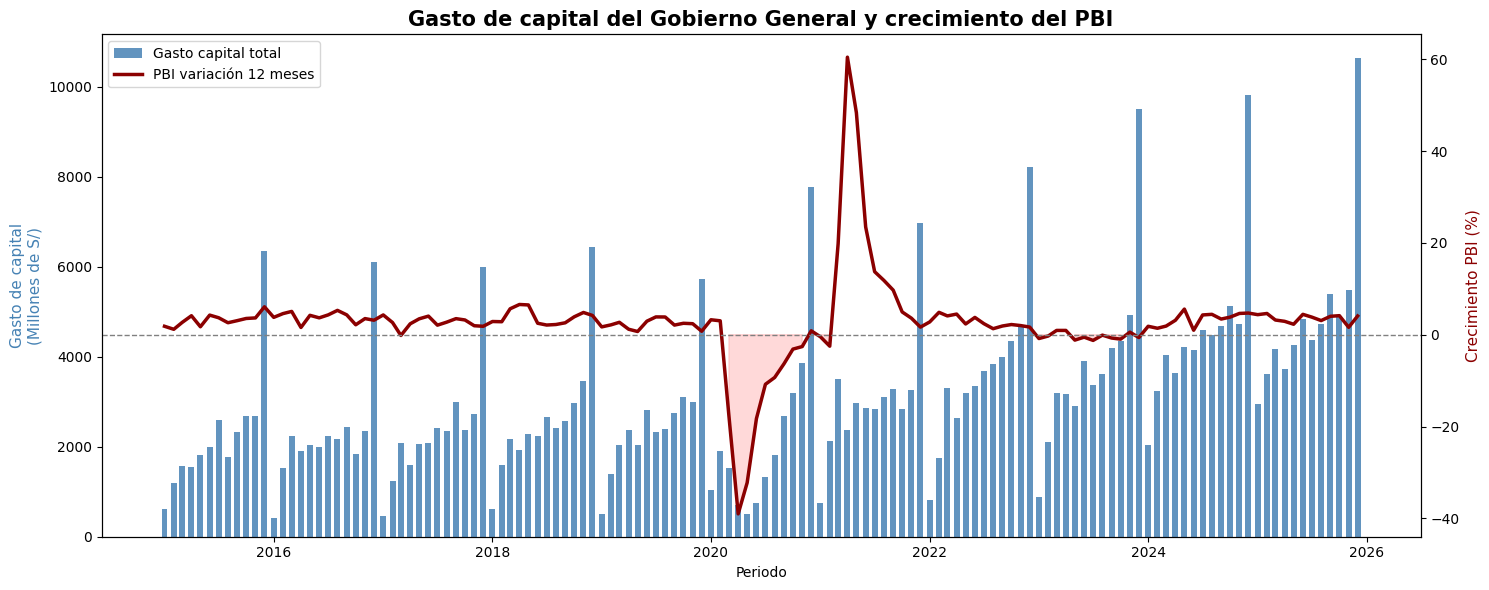

In [13]:
# gasto de capital del Gobierno General y crecimiento del PBI
df_g4 = dataset_nacional.copy()
df_g4["fecha"] = pd.to_datetime(df_g4["anio"].astype(str) + "-" + df_g4["mes"].astype(str) + "-01")
df_g4 = df_g4.sort_values("fecha")

fig, ax1 = plt.subplots(figsize=(15, 6))
ax1.bar(df_g4["fecha"], df_g4["gasto_capital_total"], width=20, color="steelblue", alpha=0.85,
        label="Gasto capital total")
ax1.set_ylabel("Gasto de capital\n(Millones de S/)", color="steelblue", fontsize=11)
ax1.set_xlabel("Periodo")

ax2 = ax1.twinx()
ax2.plot(df_g4["fecha"], df_g4["pbi_var12m_pct"], color="darkred", linewidth=2.5, label="PBI variación 12 meses")
ax2.set_ylabel("Crecimiento PBI (%)", color="darkred", fontsize=11)
ax2.fill_between(df_g4["fecha"], df_g4["pbi_var12m_pct"], 0, where=df_g4["pbi_var12m_pct"] < 0,
                  color="red", alpha=0.15)
ax2.axhline(0, color="gray", linestyle="--", linewidth=1)

lineas1, etiquetas1 = ax1.get_legend_handles_labels()
lineas2, etiquetas2 = ax2.get_legend_handles_labels()
ax2.legend(lineas1 + lineas2, etiquetas1 + etiquetas2, loc="upper left")

plt.title("Gasto de capital del Gobierno General y crecimiento del PBI", fontsize=15, fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Gráfico 5: Composición del gasto de capital por nivel de gobierno

El gráfico muestra la composición mensual del gasto de capital del Gobierno General desagregado en tres niveles: nacional, regional y local.

El área acumulada permite identificar qué nivel de gobierno tiene mayor participación en la inversión pública y cómo cambia su contribución a lo largo del tiempo.

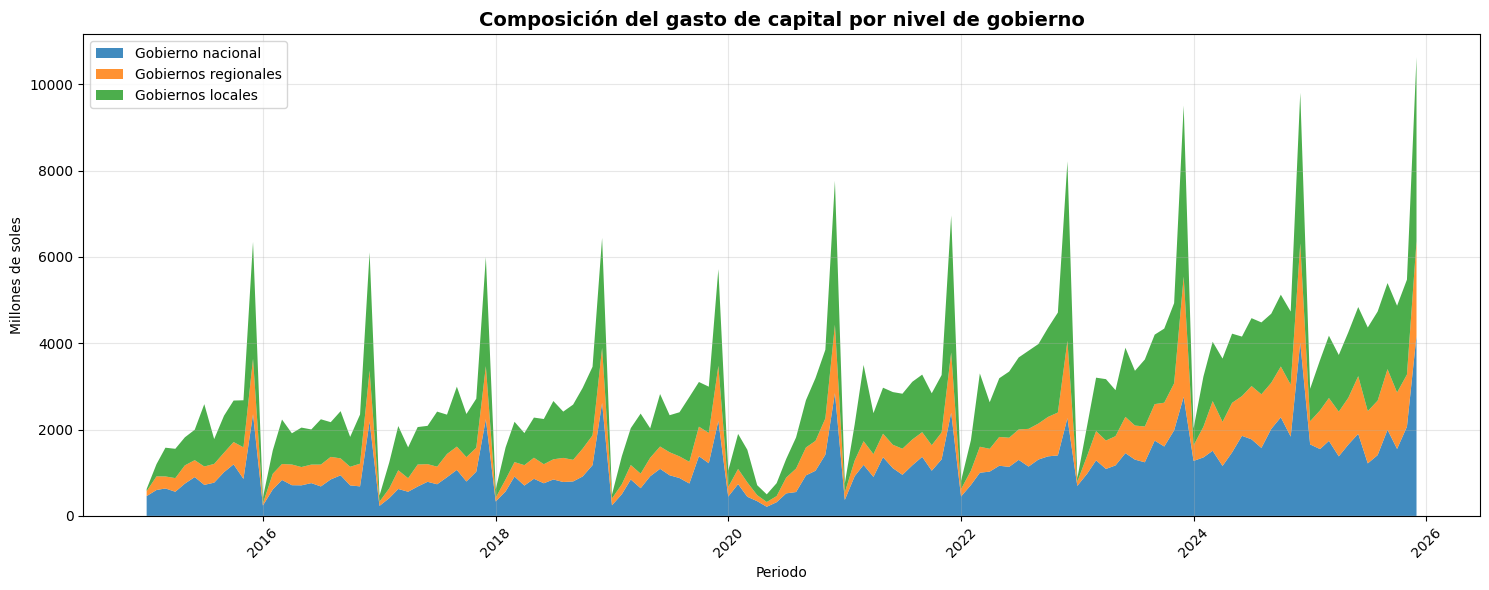

In [14]:
#composición del gasto de capital por nivel de gobierno
df_g5 = dataset_nacional.copy()
df_g5["fecha"] = pd.to_datetime(df_g5["anio"].astype(str) + "-" + df_g5["mes"].astype(str) + "-01")
df_g5 = df_g5.sort_values("fecha")

plt.figure(figsize=(15, 6))
plt.stackplot(df_g5["fecha"],
              df_g5["gasto_capital_nacional"], df_g5["gasto_capital_regional"], df_g5["gasto_capital_local"],
              labels=["Gobierno nacional", "Gobiernos regionales", "Gobiernos locales"], alpha=0.85)
estilo_grafico("Composición del gasto de capital por nivel de gobierno", "Periodo", "Millones de soles",
               leyenda={"loc": "upper left"}, rot=45)
plt.show()
# permite observar qué nivel de gobierno concentra la mayor participación del gasto de capital.

## Gráfico 6: Estacionalidad mensual del gasto de capital total

El heatmap muestra la distribución mensual del gasto de capital total a lo largo de los años analizados.

Cada celda representa el monto ejecutado en un determinado mes y año, permitiendo identificar patrones estacionales en la ejecución presupuestal, como concentraciones de gasto hacia determinados meses.

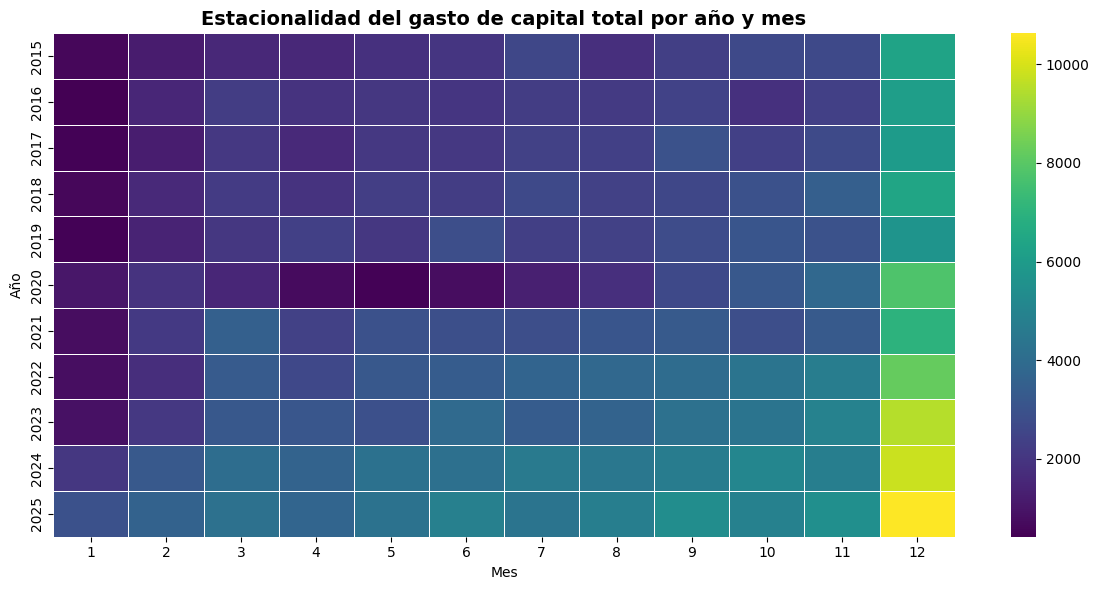

In [15]:
#estacionalidad mensual del gasto de capital total
tabla_gasto = dataset_nacional.pivot_table(index="anio", columns="mes", values="gasto_capital_total", aggfunc="sum")

plt.figure(figsize=(12, 6))
sns.heatmap(tabla_gasto, cmap="viridis", annot=False, fmt=".0f", linewidths=0.5)
estilo_grafico("Estacionalidad del gasto de capital total por año y mes", "Mes", "Año", grid=False)
plt.show()
# permite identificar meses con mayor ejecución y patrones repetitivos de gasto público.

## Gráfico 7: Matriz de correlación entre variables económicas y gasto de capital

La matriz muestra la correlación lineal de Pearson entre las principales variables económicas y fiscales obtenidas del BCRP.

Los valores positivos indican movimientos conjuntos entre variables, mientras que los valores negativos representan movimientos opuestos.

La correlación permite identificar relaciones iniciales entre gasto público, actividad económica y otros indicadores macroeconómicos, sin implicar relaciones causales.

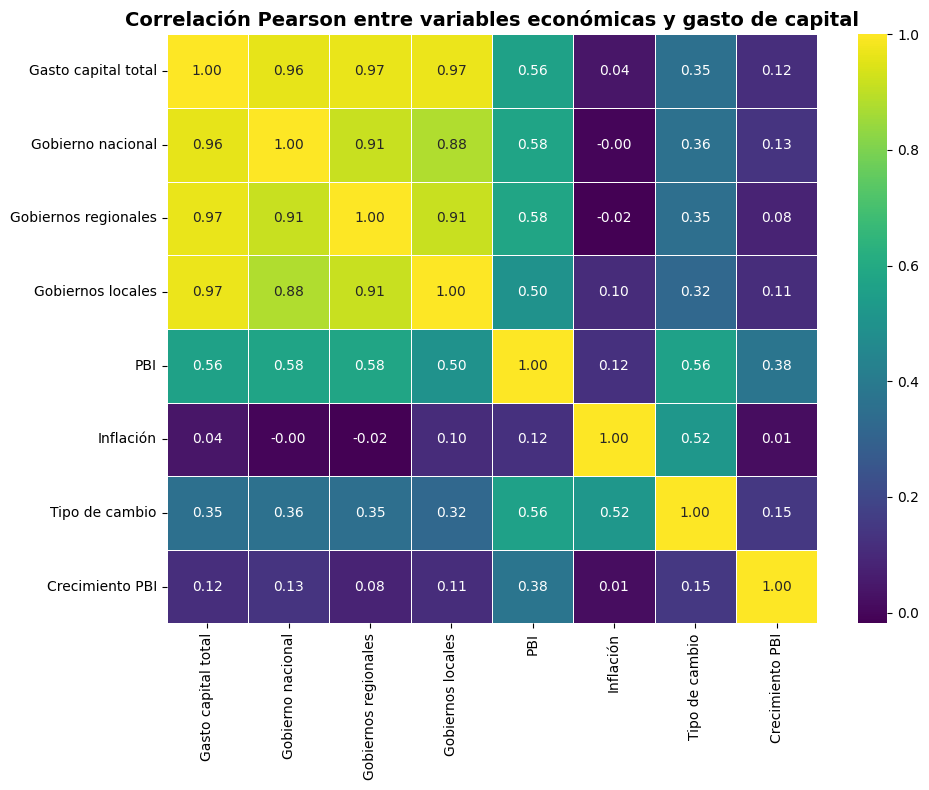

In [16]:
#matriz de correlación entre variables económicas y gasto de capital
variables_corr = {
    "gasto_capital_total": "Gasto capital total", "gasto_capital_nacional": "Gobierno nacional",
    "gasto_capital_regional": "Gobiernos regionales", "gasto_capital_local": "Gobiernos locales",
    "pbi_indice_desest": "PBI", "ipc_var12m": "Inflación", "tipo_cambio": "Tipo de cambio",
    "pbi_var12m_pct": "Crecimiento PBI",
}
matriz_corr = dataset_nacional[list(variables_corr)].rename(columns=variables_corr).corr(method="pearson")

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="viridis", linewidths=0.5)
estilo_grafico("Correlación Pearson entre variables económicas y gasto de capital", grid=False)
plt.show()
#permite identificar qué variables presentan mayor asociación lineal.

---
# 6. Validación y cierre del proyecto

Problema principal: para analizar el gasto de capital peruano y su relación con el PBI, la inflación y el tipo de cambio, se requiere organizar series económicas de manera consistente y reproducible.

La base mensual del BCRP permite responder a este problema mediante estadísticas descriptivas, gráficos, estacionalidad y correlaciones. Las asociaciones estadísticas no demuestran causalidad.

Cambio de alcance: inicialmente se incluyeron indicadores de Perú y otros países del Banco Mundial. Se retiraron de la versión final debido a dificultades intermitentes de descarga y cobertura parcial en algunas consultas, y porque la comparación regional era complementaria. La variable de efectividad gubernamental sí llegó a recuperarse en una ejecución anterior; no se afirma que fuera inexistente. Este cambio evita depender de datos internacionales en la entrega final.

En esta sección comprobamos paso a paso la calidad de los datos nacionales y la relación entre objetivos y resultados.


## 6.1 cierre

Trabajaremos con una copia de la base nacional. Así no se modifican los datos usados en los gráficos anteriores.

In [17]:
#Copiamos los datos y elegimos el periodo de estudio
cierre = dataset_nacional.copy()
cierre = cierre[cierre["anio"].between(2015, 2025)].copy()
cierre = cierre.sort_values(["anio", "mes"])

columnas = ["anio", "mes", "gasto_capital_total", "gasto_capital_nacional",
            "gasto_capital_regional", "gasto_capital_local", "pbi_indice_desest",
            "pbi_var12m_pct", "ipc_var12m", "tipo_cambio"]
componentes = ["gasto_capital_nacional", "gasto_capital_regional", "gasto_capital_local"]

for columna in columnas:
    if columna not in cierre.columns:
        raise ValueError("Falta una variable importante: " + columna)

print("Filas de la base nacional:", len(cierre))
display(cierre.head())

Filas de la base nacional: 132


,anio,mes,gasto_capital_local,gasto_capital_nacional,gasto_capital_regional,gasto_capital_total,ipc_var12m,pbi_indice_desest,tipo_cambio,pbi_var12m_pct
0,2015,1,48.315538,458.975986,114.974780,622.266305,3.073263,147.756580,3.005525,1.856552
1,2015,2,283.383003,600.168246,316.163734,1199.714982,2.768585,148.530398,3.078525,1.195668
2,2015,3,665.954009,635.794698,278.449275,1580.197982,3.020199,149.734247,3.091682,2.691334
3,2015,4,678.795911,559.522726,316.485090,1554.803727,3.017413,152.471072,3.119953,4.151282
4,2015,5,649.974407,747.955830,422.869169,1820.799406,3.366202,148.001598,3.150450,1.749981


## Revisar meses duplicados y faltantes

Comprobamos si tenemos un registro por mes entre enero de 2015 y diciembre de 2025.

In [18]:
# 7.2 Revisión de los meses
cierre["fecha"] = pd.to_datetime(dict(year=cierre["anio"], month=cierre["mes"], day=1))
meses_esperados = pd.date_range("2015-01-01", "2025-12-01", freq="MS")
meses_ausentes = meses_esperados.difference(cierre["fecha"])
duplicados = cierre.duplicated(subset=["anio", "mes"]).sum()

print("Meses esperados:", len(meses_esperados))
print("Meses ausentes:", len(meses_ausentes))
print("Meses duplicados:", duplicados)
if len(meses_ausentes) > 0:
    print("Meses que faltan:", meses_ausentes.strftime("%Y-%m").tolist())

Meses esperados: 132
Meses ausentes: 0
Meses duplicados: 0


## Revisar datos faltantes

Contamos cuántos valores faltan en cada variable y el porcentaje de observaciones disponibles.

In [19]:
# 7.3 Cantidad de datos faltantes por variable
serie_faltantes = cierre[columnas].isna().sum().to_frame("faltantes")
serie_faltantes["cobertura_pct"] = ((1 - serie_faltantes["faltantes"] / len(cierre)) * 100).round(1)
print("Cobertura de las variables nacionales:")
display(serie_faltantes)

Cobertura de las variables nacionales:


,faltantes,cobertura_pct
anio,0,100.0
mes,0,100.0
gasto_capital_total,0,100.0
gasto_capital_nacional,0,100.0
gasto_capital_regional,0,100.0
gasto_capital_local,0,100.0
pbi_indice_desest,0,100.0
pbi_var12m_pct,0,100.0
ipc_var12m,0,100.0
tipo_cambio,0,100.0


## Comprobar la suma del gasto

Revisamos si el gasto de capital total coincide aproximadamente con la suma del gasto nacional, regional y local. Se permite una diferencia de hasta S/ 1 millón por posibles redondeos.

In [20]:
# Comprobamos los componentes del gasto
filas_completas = cierre[["gasto_capital_total"] + componentes].notna().all(axis=1)
cierre["suma_niveles"] = cierre[componentes].sum(axis=1, min_count=3)
cierre["diferencia_niveles"] = cierre["gasto_capital_total"] - cierre["suma_niveles"]
inconsistencias = cierre[filas_completas & (cierre["diferencia_niveles"].abs() > 1)].copy()

print("Meses con diferencia mayor a S/ 1 millón:", len(inconsistencias))
if not inconsistencias.empty:
    display(inconsistencias[["fecha", "gasto_capital_total", "suma_niveles", "diferencia_niveles"]].head())

Meses con diferencia mayor a S/ 1 millón: 0


##Resumen de las verificaciones

Reunimos los controles anteriores en una tabla sencilla que se podrá utilizar en el informe.

In [21]:
# Tabla de calidad
controles = pd.DataFrame({
    "control": ["Filas mensuales", "Meses ausentes", "Meses duplicados",
                "Diferencias de gasto mayores a S/ 1 millón"],
    "resultado": [len(cierre), len(meses_ausentes), int(duplicados), len(inconsistencias)]
})
display(controles)

,control,resultado
0,Filas mensuales,132
1,Meses ausentes,0
2,Meses duplicados,0
3,Diferencias de gasto mayores a S/ 1 millón,0


##Gasto promedio y variabilidad

Calculamos el gasto promedio mensual y qué tanto varía alrededor de ese promedio.

In [22]:
#Resumen del gasto de capital
media_gasto = cierre["gasto_capital_total"].mean()
desviacion_gasto = cierre["gasto_capital_total"].std()
variacion_pct = desviacion_gasto / media_gasto * 100 if media_gasto != 0 else float("nan")

print("Gasto promedio mensual: S/", round(media_gasto, 2), "millones")
print("Coeficiente de variación:", round(variacion_pct, 2), "%")

Gasto promedio mensual: S/ 3122.76 millones
Coeficiente de variación: 58.87 %


## Participación por nivel de gobierno

Observamos qué porcentaje representa el gasto nacional, regional y local respecto al gasto total de los meses con información completa.

In [23]:
# Participación del gasto por nivel de gobierno
datos_completos = cierre[filas_completas]
total_gasto = datos_completos["gasto_capital_total"].sum()
participaciones = (datos_completos[componentes].sum() / total_gasto * 100).round(2)
participaciones.name = "participacion_pct"
print("Participación por nivel de gobierno (%):")
display(participaciones.to_frame())

Participación por nivel de gobierno (%):


,participacion_pct
gasto_capital_nacional,37.26
gasto_capital_regional,21.96
gasto_capital_local,40.78


##Estacionalidad del gasto

Comparamos el gasto promedio de cada mes para identificar en qué meses se concentra más o menos gasto.

In [24]:
# Promedio mensual del gasto
estacionalidad = cierre.groupby("mes")["gasto_capital_total"].agg(["mean", "count"])
estacionalidad = estacionalidad.rename(columns={"mean": "gasto_promedio_millones", "count": "observaciones"})
mes_mayor = estacionalidad["gasto_promedio_millones"].idxmax()
mes_menor = estacionalidad["gasto_promedio_millones"].idxmin()

print("Mes con mayor gasto promedio:", mes_mayor)
print("Mes con menor gasto promedio:", mes_menor)
display(estacionalidad.round(2))

Mes con mayor gasto promedio: 12
Mes con menor gasto promedio: 1


,gasto_promedio_millones,observaciones
mes,,
1,1007.07,11
2,1967.24,11
3,2714.01,11
4,2328.69,11
5,2571.45,11
6,2820.05,11
7,2942.99,11
8,2974.04,11
9,3390.76,11


## Relación con los indicadores económicos

Calculamos la correlación de Pearson entre el gasto de capital y el PBI, inflación y tipo de cambio. Una correlación no demuestra causalidad.

In [25]:
# correlaciones del gasto con indicadores económicos
indicadores = ["pbi_indice_desest", "pbi_var12m_pct", "ipc_var12m", "tipo_cambio"]
relaciones = []

for indicador in indicadores:
    datos_pares = cierre[["gasto_capital_total", indicador]].dropna()
    correlacion = datos_pares["gasto_capital_total"].corr(datos_pares[indicador])
    relaciones.append({"indicador": indicador,
                       "observaciones_pares": len(datos_pares),
                       "pearson_r": correlacion})

tabla_correlaciones = pd.DataFrame(relaciones)
print("Correlaciones calculadas con datos mensuales disponibles:")
display(tabla_correlaciones.round(3))

Correlaciones calculadas con datos mensuales disponibles:


,indicador,observaciones_pares,pearson_r
0,pbi_indice_desest,132,0.563
1,pbi_var12m_pct,132,0.116
2,ipc_var12m,132,0.038
3,tipo_cambio,132,0.352


## Respuesta al problema principal

La información de gasto de capital y los indicadores macroeconómicos del Perú quedó organizada en una base mensual del BCRP, con variables y periodos identificables. Esta base permite estudiar la evolución del gasto, su distribución entre niveles de gobierno, la estacionalidad y las correlaciones con el PBI, la inflación y el tipo de cambio.

Producto: base de datos mensual, tablas, gráficos y código que puede ejecutarse nuevamente con la fuente oficial.

Limitaciones: los valores monetarios son nominales; las correlaciones no permiten inferir efectos causales; y la calidad del resultado depende de la cobertura que entregue la API del BCRP. La comparación internacional quedó fuera del alcance final.


## Objetivos y cambios de alcance

| Objetivo | Evidencia en el notebook | Estado |
|---|---|---|
| Reunir indicadores fiscales y macroeconómicos de Perú | Base mensual del BCRP | Verificar cobertura final |
| Describir el gasto por nivel de gobierno | Gráfico de composición y participaciones | Desarrollado |
| Identificar estacionalidad | Mapa de calor y promedios mensuales | Desarrollado |
| Examinar relaciones macroeconómicas | Matriz y tabla de correlaciones | Análisis descriptivo, no causal |
| Presentar un producto reutilizable | Notebook y archivos CSV | Probar ejecución completa en Colab |
| Comparar indicadores internacionales | Se retiró del alcance final | Documentado como pendiente opcional |

Registro del cambio: la comparación con otros países y los indicadores anuales del Banco Mundial se retiraron para dar prioridad al problema nacional y a una entrega que se pueda validar. Algunas consultas internacionales devolvieron errores 502 o resultados parciales, aunque se recuperaron otros indicadores. Esto no invalida los datos nacionales del BCRP.

Para cumplir el instructivo del profesor, la revisión por interesados y la retrospectiva del equipo deberán registrarse por separado con fechas y participantes reales; no se presumen aprobaciones.




Exportamos las tablas en CSV para poder incluirlas en el informe académico y documentar lo realizado.

In [26]:
import os
os.makedirs("resultados_cierre", exist_ok=True)

dataset_nacional.to_csv("resultados_cierre/dataset_nacional_mensual.csv", index=False)
controles.to_csv("resultados_cierre/controles_calidad.csv", index=False)
serie_faltantes.to_csv("resultados_cierre/cobertura_variables.csv")
inconsistencias.to_csv("resultados_cierre/diferencias_contables.csv", index=False)
tabla_correlaciones.to_csv("resultados_cierre/correlaciones_gasto.csv", index=False)
participaciones.to_csv("resultados_cierre/participacion_niveles.csv")
estacionalidad.to_csv("resultados_cierre/estacionalidad_mensual.csv")

print("Resultados nacionales guardados en resultados_cierre")


Resultados nacionales guardados en resultados_cierre


---
#Proyección de referencia y prueba de estrés del gasto de capital

Objetivo: observar cómo cambiaría el gasto de capital del Gobierno General en 2026 bajo distintos escenarios hipotéticos.

Este ejercicio complementa el análisis histórico de 2015 a 2025. No es una predicción oficial, ni demuestra cómo cambiaría el PBI. Tampoco reemplaza las conclusiones de la sección 7.

Método sencillo: para cada mes de 2026 usamos el promedio del gasto registrado en el mismo mes de 2023, 2024 y 2025. Así conservamos la estacionalidad observada. Después aplicamos reducciones simuladas de 5%, 10% y 20%.

Importante: los porcentajes son supuestos académicos que hemos elegido para ilustrar sensibilidad. No son estimaciones oficiales del BCRP. Los montos mantienen la misma unidad del gasto histórico (millones de soles corrientes), por lo que no están corregidos por inflación.

## Revisar los datos usados para la proyección

Primero comprobamos que existan los tres últimos años y los doce meses de cada año. Sin una base completa no debemos presentar cifras proyectadas.

In [27]:
# Datos históricos usados para la proyección
historico = dataset_nacional[dataset_nacional["anio"].isin([2023, 2024, 2025])].copy()
historico = historico[["anio", "mes", "gasto_capital_total"]]
historico["gasto_capital_total"] = pd.to_numeric(historico["gasto_capital_total"], errors="coerce")

# Se necesitan 36 meses válidos y no repetidos.
if len(historico) != 36 or historico.duplicated(["anio", "mes"]).any():
    raise ValueError("La proyección requiere los 36 meses de 2023 a 2025, sin duplicados.")
if historico["gasto_capital_total"].isna().any():
    raise ValueError("Hay valores de gasto faltantes entre 2023 y 2025.")
if (historico["gasto_capital_total"] < 0).any():
    raise ValueError("Revisa los montos negativos de gasto antes de continuar.")

display(historico.groupby("anio")["mes"].nunique().rename("meses_disponibles"))


,meses_disponibles
anio,
2023,12
2024,12
2025,12


##Calcular la proyección de referencia para 2026

El valor esperado de cada mes se obtiene calculando el promedio del mismo mes durante los tres años anteriores. Es una **referencia estadística simple**, no un modelo econométrico de pronóstico.

In [28]:
# Referencia mensual de 2026: promedio del mismo mes en 2023-2025
proyeccion = historico.groupby("mes")["gasto_capital_total"].mean().reset_index()
proyeccion = proyeccion.rename(columns={"gasto_capital_total": "referencia"})
proyeccion["anio"] = 2026
proyeccion = proyeccion.sort_values("mes")
display(proyeccion[["anio", "mes", "referencia"]].round(2))


,anio,mes,referencia
0,2026,1,1948.25
1,2026,2,2977.28
2,2026,3,3804.50
3,2026,4,3514.52
4,2026,5,3797.35
5,2026,6,4297.30
6,2026,7,4103.52
7,2026,8,4281.39
8,2026,9,4760.58
9,2026,10,4778.78


##Construir los escenarios leve, moderado y severo

Para comparar escenarios suponemos que el gasto se reduce frente a la referencia de 2026 en:

- Leve: 5% menos gasto.
- Moderado: 10% menos gasto.
- Severo: 20% menos gasto.

Los tres porcentajes son hipotéticos y se aplican por igual a todos los meses; no representan una estimación de riesgo de ocurrencia.

In [29]:
#Simulación: tres reducciones hipotéticas del gasto de Perú
proyeccion["leve"] = proyeccion["referencia"] * 0.95
proyeccion["moderado"] = proyeccion["referencia"] * 0.90
proyeccion["severo"] = proyeccion["referencia"] * 0.80

display(proyeccion[["mes", "referencia", "leve", "moderado", "severo"]].round(2))


,mes,referencia,leve,moderado,severo
0,1,1948.25,1850.83,1753.42,1558.60
1,2,2977.28,2828.41,2679.55,2381.82
2,3,3804.50,3614.28,3424.05,3043.60
3,4,3514.52,3338.79,3163.07,2811.61
4,5,3797.35,3607.48,3417.62,3037.88
5,6,4297.30,4082.44,3867.57,3437.84
6,7,4103.52,3898.34,3693.17,3282.81
7,8,4281.39,4067.32,3853.25,3425.11
8,9,4760.58,4522.55,4284.52,3808.47
9,10,4778.78,4539.84,4300.90,3823.02


## Gráfico de evolución mensual de los escenarios

Este gráfico permite ver las diferencias entre los cuatro caminos y conservar los picos estacionales del gasto.

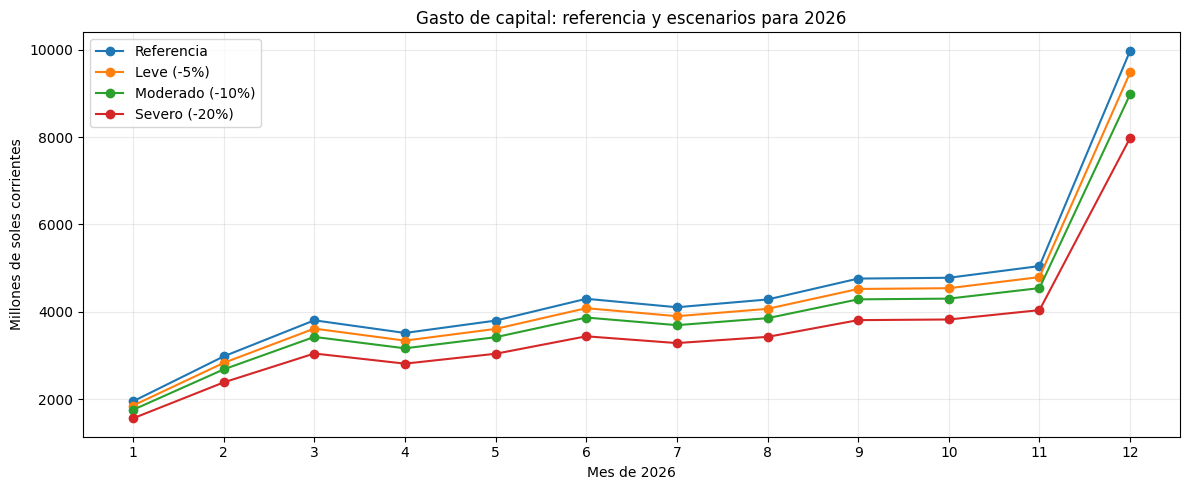

In [30]:
# 8.4 Dibujamos la referencia y los tres escenarios
plt.figure(figsize=(12, 5))
plt.plot(proyeccion["mes"], proyeccion["referencia"], marker="o", label="Referencia")
plt.plot(proyeccion["mes"], proyeccion["leve"], marker="o", label="Leve (-5%)")
plt.plot(proyeccion["mes"], proyeccion["moderado"], marker="o", label="Moderado (-10%)")
plt.plot(proyeccion["mes"], proyeccion["severo"], marker="o", label="Severo (-20%)")
plt.title("Gasto de capital: referencia y escenarios para 2026")
plt.xlabel("Mes de 2026")
plt.ylabel("Millones de soles corrientes")
plt.xticks(range(1, 13))
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


**8.5 Comparar los resultados anuales

Resumimos cuánto gasto acumulado presenta cada escenario y cuánto se reduce respecto a la referencia. Son diferencias aritméticas derivadas de nuestros supuestos, no pérdidas económicas comprobadas.

Comparación anual de los escenarios:


,escenario,total_millones,diferencia_millones,variacion_pct
0,referencia,53290.44,0.00,0.0
1,leve,50625.92,-2664.52,-5.0
2,moderado,47961.40,-5329.04,-10.0
3,severo,42632.35,-10658.09,-20.0


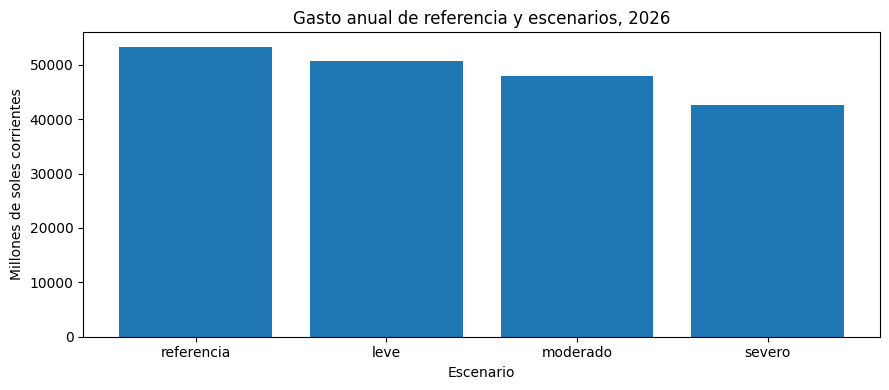

In [31]:
# 8.5 Sumamos los doce meses de cada escenario
nombres = ["referencia", "leve", "moderado", "severo"]
totales = []
total_referencia = proyeccion["referencia"].sum()

for nombre in nombres:
    total = proyeccion[nombre].sum()
    diferencia = total - total_referencia
    totales.append({"escenario": nombre, "total_millones": total,
                    "diferencia_millones": diferencia,
                    "variacion_pct": (total / total_referencia - 1) * 100})

resumen_estres = pd.DataFrame(totales)
print("Comparación anual de los escenarios:")
display(resumen_estres.round(2))

plt.figure(figsize=(9, 4))
plt.bar(resumen_estres["escenario"], resumen_estres["total_millones"])
plt.title("Gasto anual de referencia y escenarios, 2026")
plt.xlabel("Escenario")
plt.ylabel("Millones de soles corrientes")
plt.tight_layout()
plt.show()


## 8.6 Interpretación para la investigación

¿Qué aporta la prueba de estrés? Muestra cuánto variaría el gasto proyectado si se aplicaran ajustes negativos de distinta intensidad a una referencia construida con datos observados. El escenario severo se aparta más del valor de referencia, mientras que el leve se mantiene más cerca.

¿Qué no podemos afirmar? No podemos concluir que esos recortes ocurrirán en 2026, que corresponden a niveles de probabilidad ni que generarán una caída determinada del PBI, porque este ejercicio no estima relaciones causales.

Limitaciones: es un promedio estacional de solo tres años, usa cifras nominales, no incorpora cambios de política fiscal ni modelos macroeconómicos. La elección de los tres choques es ilustrativa. Para un pronóstico formal habría que comparar métodos y validar errores fuera de muestra.

Relación con el problema principal: la simulación muestra una posible aplicación práctica de la base integrada del proyecto, sin alterar su alcance histórico ni reemplazar el cierre técnico de la sección 7.

## Guardar las tablas de la simulación

Exportamos resultados por mes y el resumen anual para usarlos en el informe y la exposición.

In [32]:
# Guardamos las dos tablas en la carpeta de cierre
import os
os.makedirs("resultados_cierre", exist_ok=True)
proyeccion.to_csv("resultados_cierre/escenarios_mensuales_2026.csv", index=False)
resumen_estres.to_csv("resultados_cierre/resumen_estres_2026.csv", index=False)
print("Archivos guardados en resultados_cierre")


Archivos guardados en resultados_cierre
